In [ ]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


# Transcription factors

In [12]:
pct_expressing_boxplot  <- function(seurat_object, gene, group.by = "seurat_clusters", sample.col = "data_folder"){
   rn = which(rownames(seurat_object@assays$RNA)==gene)
ggtheme = function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

df = data.frame(grouping_var = seurat_object@meta.data[[group.by]],
               value = seurat_object@assays$RNA@counts[rn,], 
               sample = seurat_object@meta.data[[sample.col]])  %>% 
mutate(expressing = if_else(value>0,1,0))  %>% 
dplyr::select(-value)  %>% 
group_by(sample, grouping_var)  %>% 
summarise(mean_expression = mean(expressing))  %>% 
pivot_wider(names_from = sample, values_from = mean_expression, values_fill = 0)  %>% 
pivot_longer(!grouping_var, names_to = "sample", values_to = "expressing")

plt = ggplot(data = df, aes(x = grouping_var, y = expressing)) +
geom_boxplot(outlier.shape = NA, aes(fill = grouping_var), alpha = 0.3) + 
  geom_dotplot(binaxis='y', stackdir='center', dotsize=0) + 
  geom_jitter(width = 0.1, height = 0.0, size = 2, aes(color = grouping_var)) +
theme_classic() +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5)) +
ggtheme() +
xlab("") + NoLegend()
    return(plt)
    }

In [13]:
DefaultAssay(gut_cdn)  <- "RNA"

Warning message:
“The `slot` argument of `FetchData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



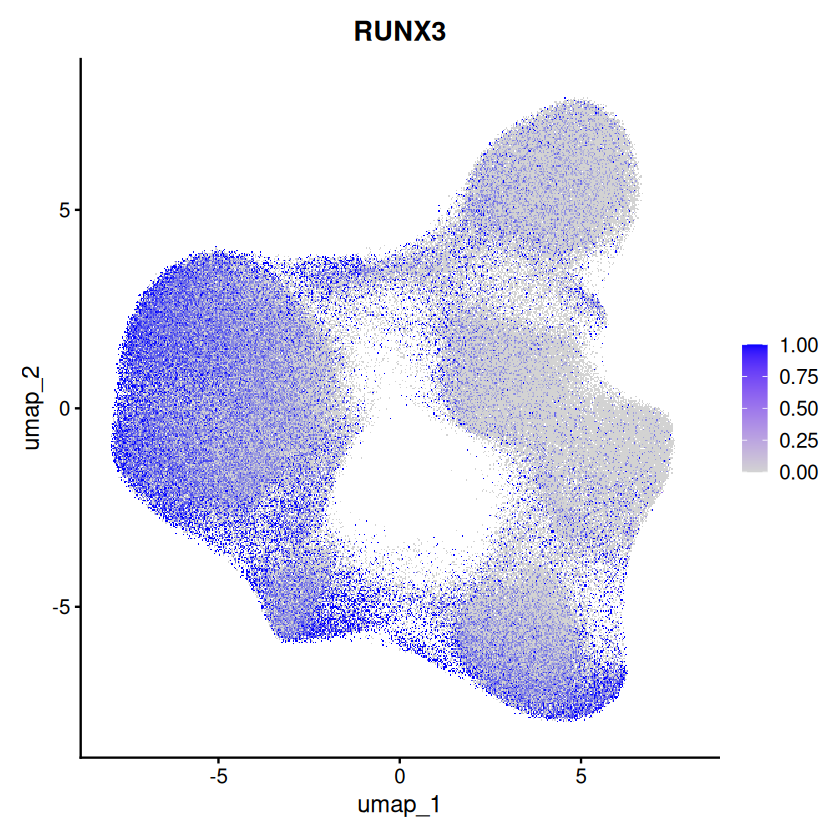

In [14]:
FeaturePlot(gut_cdn, features = "RUNX3", max.cutoff = 1)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



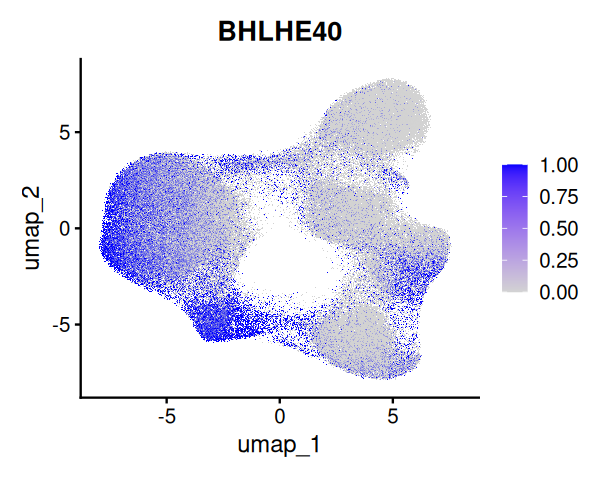

In [137]:
FeaturePlot(gut_cdn, features = "BHLHE40", max.cutoff = 1)

In [ ]:
FeaturePlot(gut_cdn, features = "BHLHE40", max.cutoff = 1)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



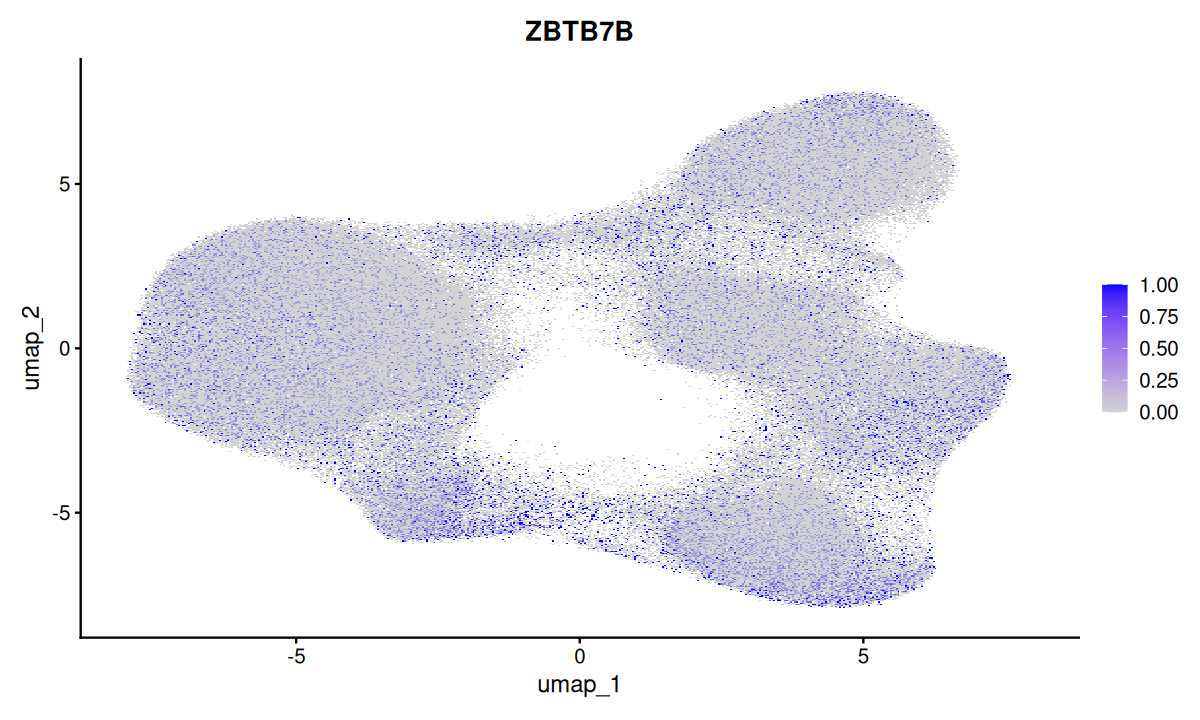

In [309]:
FeaturePlot(gut_cdn, features = "ZBTB7B", max.cutoff = 1)

In [15]:
markers2  <- c("IKZF2", "IKZF3", "EOS", "ZEB2", "HOPX", "LEF1", "TCF7", 
              "STAT1", "STAT5A",  "PRDM1","IRF4",
              "ZBTB7B", "RUNX3","TBX21","EOMES","RORA",
              "RORC", "BATF","BACH2","BHLHE40", "IKZF4","ZNF683")

avgexp = AverageExpression(gut_cdn, features = markers2, group.by = "seurat_clusters",
                          assay = "RNA")

As of Seurat v5, we recommend using AggregateExpression to perform pseudo-bulk analysis.
This message is displayed once per session.
First group.by variable `seurat_clusters` starts with a number, appending `g` to ensure valid variable names
This message is displayed once every 8 hours.
Warning message:
“The following 1 features were not found in the RNA assay: EOS”


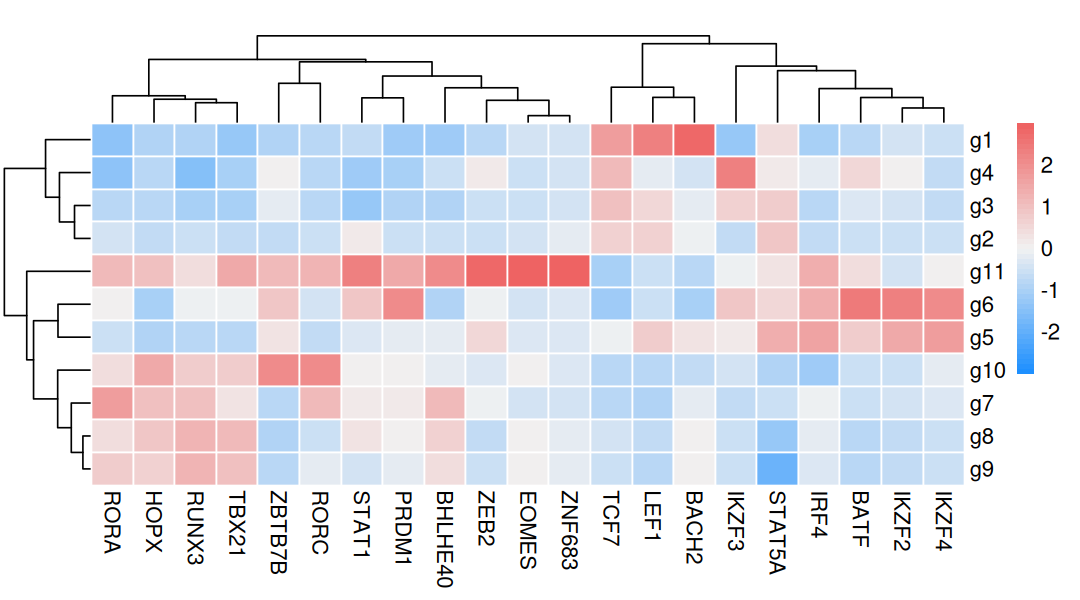

In [16]:
options(repr.plot.width = 9, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13)

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13)

In [20]:
markers2  <- unique(c('TBX21', 'EOMES', 'TCF7', 'LEF1', 'BCL6', 'PRDM1', 'IRF4', 'BATF', 'BATF3', 'TOX', 'TOX2', 'ZEB2', 'ZEB1', 'ID2', 'ID3', 'BACH2', 'ZBTB7B', 'RUNX3', 'RUNX1', 'BCL11B', 'TCF3', 'TCF12', 'GATA3', 'RORC', 'RORA', 'FOXP3', 'IKZF2', 'IKZF1', 'IKZF3', 'STAT1', 'STAT3', 'STAT4', 'STAT5A', 'STAT5B', 'STAT6', 'NFATC1', 'NFATC2', 'RELA', 'NFKB1', 'NFKB2', 'REL', 'BCL10', 'FOXO1', 'FOXO3', 'FOXP1', 'NR4A1', 'NR4A2', 'NR4A3', 'ZBTB16', 'AHR', 'HIF1A', 'BHLHE40', 'EGR2', 'EGR3', 'EGR1', 'ETS1', 'ELF4', 'KLF2', 'KLF3', 'KLF13', 'KLF6', 'MYB', 'BCL3', 'ZFP683', 'PRDM1', 'RBPJ', 'NOTCH1', 'ZBTB20', 'TCF7', 'MAF', 'BCL6B', 'ZFP683', 'ZBTB32', 'TOX2', 'POU2F2', 'NR3C1', 'BHLHE41', 'NR2F6', 'HIC1', 'BCL6', 'TFAP4', 'SNAI3', 'BATF', 'MAZR', 'ZBTB7A', 'SOX13', 'SOX4', 'NFIL3', 'IRF4', 'JUN', 'JUNB', 'FOS', 'FOSL2', 'E2F1', 'SMAD3', 'SMAD2', 'RFX5', 'HHEX', 'ARNTL', 'NRF1', 'PPARG', 'NR1D1',"IKZF1","IKZF3","IKZF4"))

In [30]:
avgexp = AverageExpression(gut_cdn, features = markers2, group.by = "seurat_clusters",
                          assay = "RNA")

Warning message:
“The following 2 features were not found in the RNA assay: ZFP683, MAZR”


In [28]:
dir.create("figures/heatmaps_tf/")

In [31]:
options(repr.plot.width = 17, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13, filename = "figures/heatmaps_tf/expression_tf.pdf", width = 17, height = 4)

In [22]:
Idents(gut_cdn)  %>% table

.
    8     1     6     7     3     9     5    11     4     2    10 
54392 51934 47505 44199 38339 31992 19573 18771 17587 11276 10888 

In [66]:
DefaultAssay(gut_cdn)  <- "RNA"
mrk_tf_rna  <- FindMarkers(gut_cdn, `ident.1` = 11, features = markers2[which(markers2 %in% rownames(gut_cdn@assays$RNA))])

In [67]:
mrk_tf_rna  %>% arrange(desc(avg_log2FC))

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
PPARG,0.000000e+00,3.6749228,0.098,0.006,0.000000e+00
EOMES,0.000000e+00,3.1321162,0.052,0.005,0.000000e+00
ZEB2,0.000000e+00,2.7589098,0.290,0.036,0.000000e+00
BATF3,2.575358e-294,2.0147763,0.023,0.004,9.426066e-290
RORC,0.000000e+00,1.9125502,0.212,0.042,0.000000e+00
E2F1,3.026331e-238,1.9004044,0.020,0.004,1.107667e-233
EGR2,0.000000e+00,1.6872173,0.057,0.014,0.000000e+00
BHLHE40,0.000000e+00,1.6094093,0.618,0.191,0.000000e+00
RBPJ,0.000000e+00,1.4619703,0.540,0.176,0.000000e+00


In [68]:
rownames(mrk_tf_rna  %>% arrange(desc(avg_log2FC))   %>% dplyr::filter(avg_log2FC>0.7))

[1] "PPARG"   "EOMES"   "ZEB2"    "BATF3"   "RORC"    "E2F1"    "EGR2"   
 [8] "BHLHE40" "RBPJ"    "NFIL3"   "NR1D1"   "PRDM1"   "TBX21"   "IRF4"   
[15] "ID2"     "STAT1"   "RUNX1"   "BCL3"    "NFATC2"

In [70]:
mr  <- rownames(mrk_tf_rna  %>% arrange(desc(avg_log2FC))   %>% dplyr::filter(avg_log2FC>0.7))

In [ ]:
avgexp = AverageExpression(gut_cdn, features = mr, group.by = "seurat_clusters",
                          assay = "RNA")

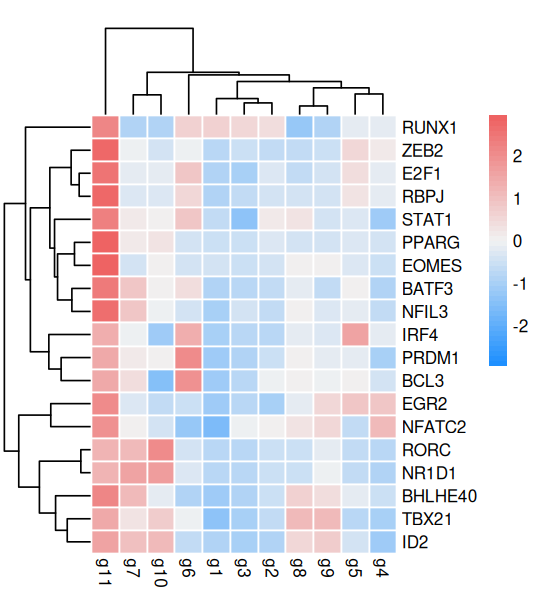

In [74]:
options(repr.plot.width = 4.5, repr.plot.height = 5)
    pheatmap::pheatmap(avgexp$RNA, main = "", 
         scale = "row", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white"
                 )

In [76]:
 options(repr.plot.width = 17, repr.plot.height = 5)
    pheatmap::pheatmap(avgexp$RNA, main = "", angle_col = 0,
         scale = "row", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                 fontsize = 13, filename = "figures/heatmaps_tf/rna_tf.pdf", width = 4.5, height = 5)

In [29]:
gut_cdn

An object of class Seurat 
74985 features across 346456 samples within 5 assays 
Active assay: CollecTRI (769 features, 0 variable features)
 2 layers present: counts, data
 4 other assays present: RNA, integrated, RNA3, pathwayswmean
 2 dimensional reductions calculated: pca, umap

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



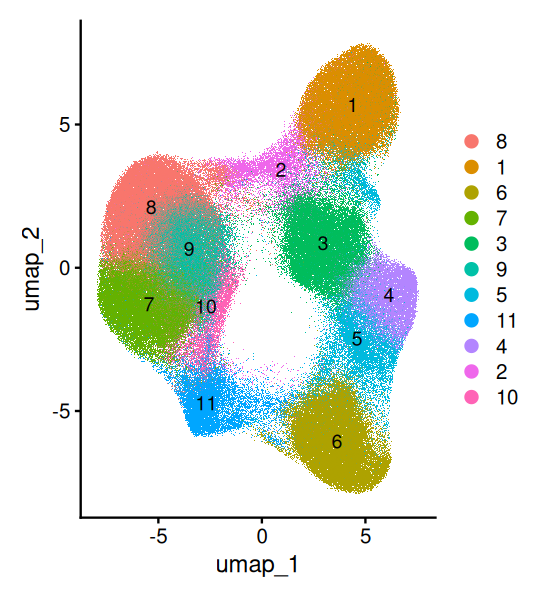

In [86]:
DimPlot(gut_cdn, label = T)

In [77]:
DefaultAssay(gut_cdn)  <- "CollecTRI"
mrk_tf_collectri  <- FindMarkers(gut_cdn, `ident.1` = 11, features = markers2[which(markers2 %in% rownames(gut_cdn@assays$CollecTRI))])

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”


In [78]:
mrk_tf_collectri %>% arrange((avg_log2FC))

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
BHLHE41,0.000000e+00,-3.3301126,0.303,0.435,0.000000e+00
BACH2,2.667356e-181,-2.3232610,0.137,0.193,2.051197e-178
TOX,0.000000e+00,-2.0197489,0.153,0.160,0.000000e+00
IKZF2,1.010591e-01,-1.5135068,0.681,0.558,1.000000e+00
KLF2,0.000000e+00,-1.4936283,0.524,0.672,0.000000e+00
LEF1,1.309208e-300,-1.3028116,0.425,0.546,1.006781e-297
NR1D1,3.643561e-242,-1.1446675,0.497,0.687,2.801898e-239
SOX4,7.853113e-22,-0.5468931,0.413,0.453,6.039044e-19
IKZF3,4.706622e-57,-0.5080918,0.564,0.482,3.619392e-54


In [87]:
mr  <- rownames(mrk_tf_collectri  %>% arrange(desc(avg_log2FC))  %>% slice_head(n = 20))

In [88]:
mr

[1] "RFX5"   "REL"    "STAT4"  "E2F1"   "NFKB1"  "RORC"   "RELA"   "TBX21" 
 [9] "EOMES"  "STAT1"  "NFATC2" "BATF"   "RUNX3"  "ELF4"   "JUN"    "STAT3" 
[17] "NFATC1" "HIF1A"  "NFKB2"  "IRF4"

In [89]:
avgexp = AverageExpression(gut_cdn, features = mr, group.by = "seurat_clusters",
                          assay = "CollecTRI")

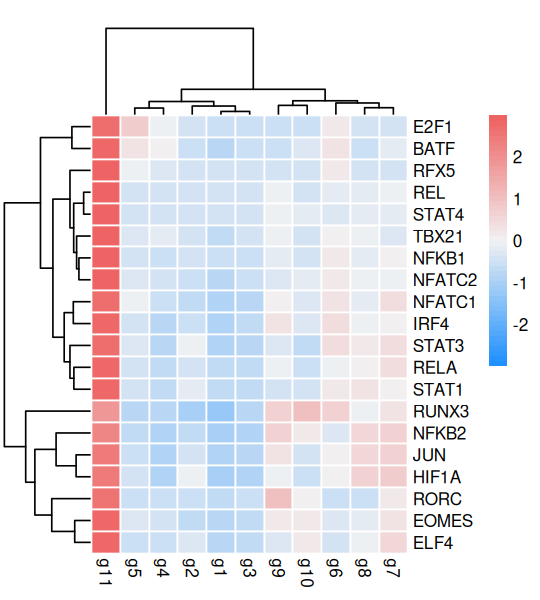

In [93]:
options(repr.plot.width = 4.5, repr.plot.height = 5)
    pheatmap::pheatmap(avgexp$CollecTRI, main = "", 
         scale = "row", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white"
                 )

In [96]:
options(repr.plot.width = 4.5, repr.plot.height = 5)
    pheatmap::pheatmap(avgexp$CollecTRI, main = "", 
         scale = "row", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                 fontsize = 13, filename = "figures/heatmaps_tf/CollecTRI_tf2.pdf", width = 4.5, height = 5)

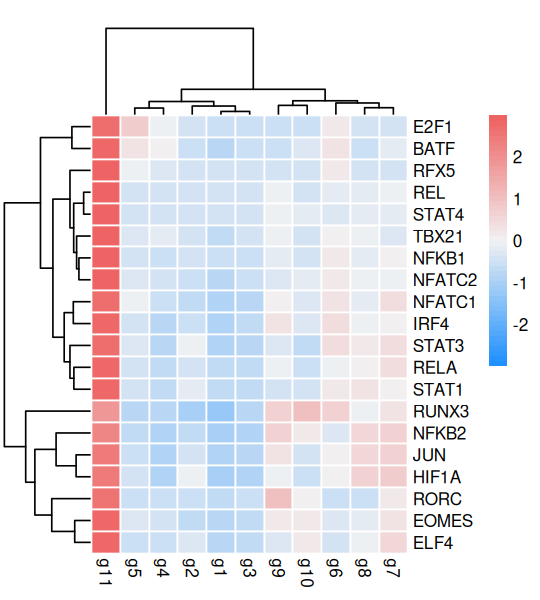

In [95]:
options(repr.plot.width = 4.5, repr.plot.height = 5)
    pheatmap::pheatmap(avgexp$CollecTRI, main = "", 
         scale = "row", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white")

In [97]:
lineage_df

barcode,Lineage1,Lineage2,Lineage3,Lineage4,Lineage5
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,2.4254398,2.4049660,2.4261019,2.4056723,2.4060933
AAACCTGCAGTCACTA-1_1193610_1_1_1,10.3124593,NA,10.3373411,NA,NA
AAACCTGCATCGGACC-1_1193610_1_1_1,10.4459095,NA,NA,NA,NA
AAACCTGTCGCCAGCA-1_1193610_1_1_1,7.7435835,NA,7.6813883,NA,NA
AAACCTGTCGCGATCG-1_1193610_1_1_1,2.6180765,2.5667506,2.6122994,2.5677228,2.5691318
AAACCTGTCTTCGGTC-1_1193610_1_1_1,0.8083148,0.8121457,0.8078510,0.8117275,0.8119254
AAACGGGAGCGTTTAC-1_1193610_1_1_1,8.1657095,NA,8.0332509,NA,NA
AAACGGGCACAGACTT-1_1193610_1_1_1,NA,14.6500606,NA,NA,NA
AAACGGGCAGGTGCCT-1_1193610_1_1_1,8.1620010,NA,8.3601454,NA,NA


## Activity in Lineage 4

## Expression in Lineage 4

In [172]:
expression_data <- gut_cdn@assays$RNA@data[which(grepl(rownames(gut_cdn@assays$RNA), pattern = "^IL")|
                                                 grepl(rownames(gut_cdn@assays$RNA), pattern = "^CCL")|
                                                 grepl(rownames(gut_cdn@assays$RNA), pattern = "^CX")|
                                                 grepl(rownames(gut_cdn@assays$RNA), pattern = "^GZM")|
                                                 grepl(rownames(gut_cdn@assays$RNA), pattern = "^GNL")|
                                                 grepl(rownames(gut_cdn@assays$RNA), pattern = "^IFN")|
                                                 grepl(rownames(gut_cdn@assays$RNA), pattern = "^STAT")|
                                                 grepl(rownames(gut_cdn@assays$RNA), pattern = "^IFN")|
                                                 grepl(rownames(gut_cdn@assays$RNA), pattern = "^TNF")|
                                                 grepl(rownames(gut_cdn@assays$RNA), pattern = "^FASLG")|
                                                 
                                                 rownames(gut_cdn@assays$RNA) %in% rownames(mrk_tf_rna  %>% arrange(desc(avg_log2FC))   %>% dplyr::filter(avg_log2FC>0.7)))
                                                 ,]

expression_data  <- t(expression_data)  %>% as.data.frame()


In [173]:
tf_df  <- cbind(expression_data, lineage_df)

In [174]:
tf_df

,TNFRSF18,TNFRSF4,TNFRSF14-AS1,TNFRSF14,TNFRSF25,TNFRSF9,TNFRSF8,TNFRSF1B,IL22RA1,IFNLR1,⋯,CXorf51A,CXorf40A,CXorf40B,IL9R,barcode,Lineage1,Lineage2,Lineage3,Lineage4,Lineage5
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,0,0.000000,0,1.876246,0.000000,0,0,0.000000,0,0,⋯,0,0.000000,0.000000,0,AAACCTGAGAGCCTAG-1_1193610_1_1_1,2.4254398,2.4049660,2.4261019,2.4056723,2.4060933
AAACCTGCAGTCACTA-1_1193610_1_1_1,0,0.000000,0,1.896455,0.000000,0,0,1.896455,0,0,⋯,0,0.000000,0.000000,0,AAACCTGCAGTCACTA-1_1193610_1_1_1,10.3124593,NA,10.3373411,NA,NA
AAACCTGCATCGGACC-1_1193610_1_1_1,0,0.000000,0,0.000000,0.000000,0,0,0.000000,0,0,⋯,0,0.000000,0.000000,0,AAACCTGCATCGGACC-1_1193610_1_1_1,10.4459095,NA,NA,NA,NA
AAACCTGTCGCCAGCA-1_1193610_1_1_1,0,0.000000,0,0.000000,0.000000,0,0,2.469177,0,0,⋯,0,0.000000,0.000000,0,AAACCTGTCGCCAGCA-1_1193610_1_1_1,7.7435835,NA,7.6813883,NA,NA
AAACCTGTCGCGATCG-1_1193610_1_1_1,0,0.000000,0,2.090159,0.000000,0,0,0.000000,0,0,⋯,0,0.000000,0.000000,0,AAACCTGTCGCGATCG-1_1193610_1_1_1,2.6180765,2.5667506,2.6122994,2.5677228,2.5691318
AAACCTGTCTTCGGTC-1_1193610_1_1_1,0,0.000000,0,0.000000,0.000000,0,0,0.000000,0,0,⋯,0,0.000000,0.000000,0,AAACCTGTCTTCGGTC-1_1193610_1_1_1,0.8083148,0.8121457,0.8078510,0.8117275,0.8119254
AAACGGGAGCGTTTAC-1_1193610_1_1_1,0,0.000000,0,2.609270,0.000000,0,0,0.000000,0,0,⋯,0,0.000000,0.000000,0,AAACGGGAGCGTTTAC-1_1193610_1_1_1,8.1657095,NA,8.0332509,NA,NA
AAACGGGCACAGACTT-1_1193610_1_1_1,0,0.000000,0,2.304910,2.451207,0,0,0.000000,0,0,⋯,0,0.000000,0.000000,0,AAACGGGCACAGACTT-1_1193610_1_1_1,NA,14.6500606,NA,NA,NA
AAACGGGCAGGTGCCT-1_1193610_1_1_1,0,0.000000,0,0.000000,0.000000,0,0,0.000000,0,0,⋯,0,0.000000,0.000000,0,AAACGGGCAGGTGCCT-1_1193610_1_1_1,8.1620010,NA,8.3601454,NA,NA


In [175]:
colnames(expression_data)  <- paste0(colnames(expression_data),"_E")

In [176]:
expression_data

,TNFRSF18_E,TNFRSF4_E,TNFRSF14-AS1_E,TNFRSF14_E,TNFRSF25_E,TNFRSF9_E,TNFRSF8_E,TNFRSF1B_E,IL22RA1_E,IFNLR1_E,⋯,IL1RAPL2_E,IL13RA2_E,IL13RA1_E,CXorf56_E,CXorf66_E,CXorf51B_E,CXorf51A_E,CXorf40A_E,CXorf40B_E,IL9R_E
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,0,0.000000,0,1.876246,0.000000,0,0,0.000000,0,0,⋯,0,0,0,0,0,0,0,0.000000,0.000000,0
AAACCTGCAGTCACTA-1_1193610_1_1_1,0,0.000000,0,1.896455,0.000000,0,0,1.896455,0,0,⋯,0,0,0,0,0,0,0,0.000000,0.000000,0
AAACCTGCATCGGACC-1_1193610_1_1_1,0,0.000000,0,0.000000,0.000000,0,0,0.000000,0,0,⋯,0,0,0,0,0,0,0,0.000000,0.000000,0
AAACCTGTCGCCAGCA-1_1193610_1_1_1,0,0.000000,0,0.000000,0.000000,0,0,2.469177,0,0,⋯,0,0,0,0,0,0,0,0.000000,0.000000,0
AAACCTGTCGCGATCG-1_1193610_1_1_1,0,0.000000,0,2.090159,0.000000,0,0,0.000000,0,0,⋯,0,0,0,0,0,0,0,0.000000,0.000000,0
AAACCTGTCTTCGGTC-1_1193610_1_1_1,0,0.000000,0,0.000000,0.000000,0,0,0.000000,0,0,⋯,0,0,0,0,0,0,0,0.000000,0.000000,0
AAACGGGAGCGTTTAC-1_1193610_1_1_1,0,0.000000,0,2.609270,0.000000,0,0,0.000000,0,0,⋯,0,0,0,0,0,0,0,0.000000,0.000000,0
AAACGGGCACAGACTT-1_1193610_1_1_1,0,0.000000,0,2.304910,2.451207,0,0,0.000000,0,0,⋯,0,0,0,0,0,0,0,0.000000,0.000000,0
AAACGGGCAGGTGCCT-1_1193610_1_1_1,0,0.000000,0,0.000000,0.000000,0,0,0.000000,0,0,⋯,0,0,0,0,0,0,0,0.000000,0.000000,0


In [177]:
colnames(expression_data)  <- gsub(colnames(expression_data)  , pattern = "E_E", replacement = "E")

In [178]:
tf_collectri  <- gut_cdn@assays$CollecTRI@counts[which(rownames(gut_cdn@assays$CollecTRI) %in% tfs),]
tf_collectri  <- t(tf_collectri)  %>% as.data.frame()

In [179]:
tf_collectri

,AHR,BACH2,BATF,BCL11B,BCL3,BCL6,BHLHE40,BHLHE41,E2F1,EGR1,⋯,TCF3,TCF7,TFAP4,TOX,ZBTB16,ZBTB32,ZBTB7A,ZBTB7B,ZEB1,ZEB2
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,0.27254945,0.0000000,4.5281559,0.6055674,-1.5685818,1.3392048,-0.5374640,0.5356416,2.42569925,2.86675671,⋯,2.5847997,1.3032320,1.2021416,-0.4326829,-0.2805685,-0.2595980,2.1412564,2.1241173,3.39728139,1.99128286
AAACCTGCAGTCACTA-1_1193610_1_1_1,3.21184588,0.0000000,3.1753977,1.5542963,-0.5554798,0.1662555,0.1874907,0.5286986,3.54059196,2.85357654,⋯,1.3431423,0.2946326,0.9482087,-0.4423572,1.1445590,-0.2654023,-0.1669520,0.9544949,1.82672592,0.77661763
AAACCTGCATCGGACC-1_1193610_1_1_1,1.69985200,0.0000000,2.5961331,4.8553982,1.8432523,-1.7647584,-0.4233655,-0.2880470,3.13323596,1.40929647,⋯,0.3697142,-0.5403586,2.6448259,2.5262063,1.1414158,-0.2044881,2.7771602,2.9983020,-0.32756868,-0.08490728
AAACCTGTCGCCAGCA-1_1193610_1_1_1,0.74124001,-1.9897774,2.2976389,-0.3106111,-0.6089132,-1.4685663,2.2332206,0.7374685,1.43596399,2.44425901,⋯,1.0057993,-0.6117676,1.1414470,2.1311909,0.9742151,-0.2315112,0.6131637,2.5580879,1.96189363,-0.09612777
AAACCTGTCGCGATCG-1_1193610_1_1_1,2.97824748,-2.1368193,0.6048257,0.9567019,-1.6265354,0.6060629,1.1378126,0.6624904,-0.02187797,4.23888522,⋯,0.8320626,1.7270997,1.4124284,-0.4049864,3.8701425,-0.2429809,1.3010799,2.4495797,2.31506696,1.21262889
AAACCTGTCTTCGGTC-1_1193610_1_1_1,1.22045823,0.0000000,0.8173175,1.0247782,-0.5790462,0.1283986,-0.4558034,-0.3101169,4.37731525,0.77620959,⋯,2.3031517,0.7947644,2.2331485,-0.3669427,2.7788271,-0.2201557,0.6722578,0.9813552,2.00235736,-0.09141277
AAACGGGAGCGTTTAC-1_1193610_1_1_1,2.32246752,0.0000000,1.3637565,1.1543783,0.8134622,0.2670796,-1.4705685,-0.2630173,2.52917792,3.75097436,⋯,2.6156750,2.5734455,-0.5721146,-0.3112124,2.5454085,-0.1867191,1.0370445,3.2594786,1.49539726,1.22683474
AAACGGGCACAGACTT-1_1193610_1_1_1,3.46659370,-3.8626314,2.2524884,1.7008561,1.2298554,-1.2601516,1.1629127,1.5715893,2.38248907,3.96663674,⋯,2.1522265,-0.6671890,1.7416593,1.8595909,1.4232988,-2.5329341,-1.2477299,2.4242332,0.50136875,0.02992458
AAACGGGCAGGTGCCT-1_1193610_1_1_1,0.77769439,-2.0849575,5.2359696,0.8806378,-0.5857278,-1.7108755,1.3589565,0.8007569,1.16387448,1.88857554,⋯,3.4056165,-0.5884735,3.1967071,-0.3711768,0.9312428,-0.2226961,2.0868826,1.2266883,2.16282837,-0.09246758


In [180]:
colnames(tf_collectri)  <- paste0(colnames(tf_collectri),"_A")

In [181]:
tf_both  <- cbind(tf_collectri, expression_data, lineage_df)

In [182]:
tf_both

,AHR_A,BACH2_A,BATF_A,BCL11B_A,BCL3_A,BCL6_A,BHLHE40_A,BHLHE41_A,E2F1_A,EGR1_A,⋯,CXorf51A_E,CXorf40A_E,CXorf40B_E,IL9R_E,barcode,Lineage1,Lineage2,Lineage3,Lineage4,Lineage5
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,0.27254945,0.0000000,4.5281559,0.6055674,-1.5685818,1.3392048,-0.5374640,0.5356416,2.42569925,2.86675671,⋯,0,0.000000,0.000000,0,AAACCTGAGAGCCTAG-1_1193610_1_1_1,2.4254398,2.4049660,2.4261019,2.4056723,2.4060933
AAACCTGCAGTCACTA-1_1193610_1_1_1,3.21184588,0.0000000,3.1753977,1.5542963,-0.5554798,0.1662555,0.1874907,0.5286986,3.54059196,2.85357654,⋯,0,0.000000,0.000000,0,AAACCTGCAGTCACTA-1_1193610_1_1_1,10.3124593,NA,10.3373411,NA,NA
AAACCTGCATCGGACC-1_1193610_1_1_1,1.69985200,0.0000000,2.5961331,4.8553982,1.8432523,-1.7647584,-0.4233655,-0.2880470,3.13323596,1.40929647,⋯,0,0.000000,0.000000,0,AAACCTGCATCGGACC-1_1193610_1_1_1,10.4459095,NA,NA,NA,NA
AAACCTGTCGCCAGCA-1_1193610_1_1_1,0.74124001,-1.9897774,2.2976389,-0.3106111,-0.6089132,-1.4685663,2.2332206,0.7374685,1.43596399,2.44425901,⋯,0,0.000000,0.000000,0,AAACCTGTCGCCAGCA-1_1193610_1_1_1,7.7435835,NA,7.6813883,NA,NA
AAACCTGTCGCGATCG-1_1193610_1_1_1,2.97824748,-2.1368193,0.6048257,0.9567019,-1.6265354,0.6060629,1.1378126,0.6624904,-0.02187797,4.23888522,⋯,0,0.000000,0.000000,0,AAACCTGTCGCGATCG-1_1193610_1_1_1,2.6180765,2.5667506,2.6122994,2.5677228,2.5691318
AAACCTGTCTTCGGTC-1_1193610_1_1_1,1.22045823,0.0000000,0.8173175,1.0247782,-0.5790462,0.1283986,-0.4558034,-0.3101169,4.37731525,0.77620959,⋯,0,0.000000,0.000000,0,AAACCTGTCTTCGGTC-1_1193610_1_1_1,0.8083148,0.8121457,0.8078510,0.8117275,0.8119254
AAACGGGAGCGTTTAC-1_1193610_1_1_1,2.32246752,0.0000000,1.3637565,1.1543783,0.8134622,0.2670796,-1.4705685,-0.2630173,2.52917792,3.75097436,⋯,0,0.000000,0.000000,0,AAACGGGAGCGTTTAC-1_1193610_1_1_1,8.1657095,NA,8.0332509,NA,NA
AAACGGGCACAGACTT-1_1193610_1_1_1,3.46659370,-3.8626314,2.2524884,1.7008561,1.2298554,-1.2601516,1.1629127,1.5715893,2.38248907,3.96663674,⋯,0,0.000000,0.000000,0,AAACGGGCACAGACTT-1_1193610_1_1_1,NA,14.6500606,NA,NA,NA
AAACGGGCAGGTGCCT-1_1193610_1_1_1,0.77769439,-2.0849575,5.2359696,0.8806378,-0.5857278,-1.7108755,1.3589565,0.8007569,1.16387448,1.88857554,⋯,0,0.000000,0.000000,0,AAACGGGCAGGTGCCT-1_1193610_1_1_1,8.1620010,NA,8.3601454,NA,NA


In [183]:
lin4  <- tf_both  %>% dplyr::select(1:360,Lineage4)  %>% 
dplyr::filter(!is.na(Lineage4))  %>% 
pivot_longer(!Lineage4, names_to = "gene", values_to = "value")

In [ ]:
## Th1

In [184]:
df_binned <-  lin4  %>% dplyr::filter(gene %in% c("IFNG_E","STAT1_A","STAT4_A","RELA_A","IL12RB2_E","TBX21_A","CXCR3_E","GZMB_E","TNF_E"))  %>% 

  mutate(pt_decile = ntile(Lineage4, 20)) %>%   # deciles 1–10
  group_by(gene, pt_decile) %>%
  summarize(
    pseudotime_mean = mean(Lineage4, na.rm = TRUE),
    expr_mean = mean(value, na.rm = TRUE),
    .groups = "drop"
  )

In [185]:
df_binned <- df_binned %>%
  group_by(gene) %>%
  mutate(
    expr_scaled = (expr_mean - min(expr_mean, na.rm = TRUE)) /
                  (max(expr_mean, na.rm = TRUE) - min(expr_mean, na.rm = TRUE))
  ) %>%
  ungroup()

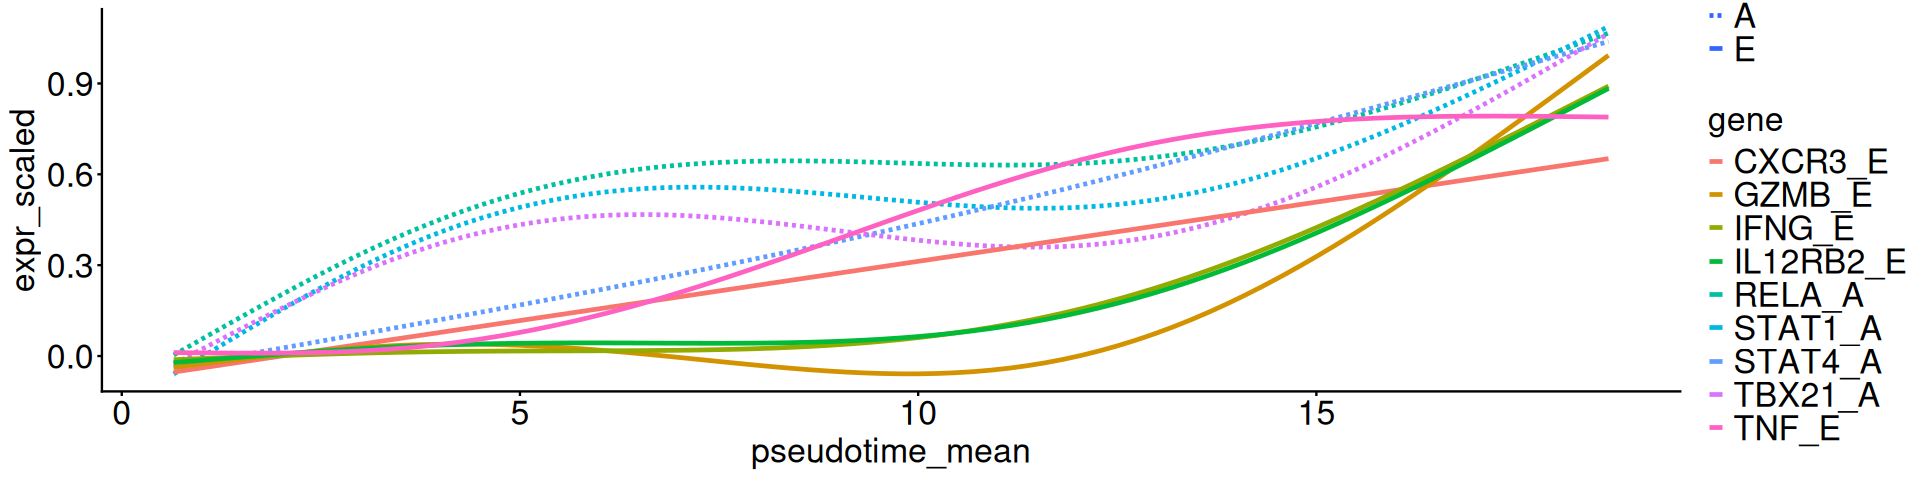

In [186]:
options(repr.plot.width = 16, repr.plot.height = 4)
df_binned  %>% 
mutate(gene_class = ifelse(grepl(gene, pattern = "_A"),"A","E"))  %>% 
ggplot(aes(
    x        = pseudotime_mean,
    y        = expr_scaled,
    linetype = gene_class,
    color = gene
  )
) +
  stat_smooth(
    method  = "gam",
    formula = y ~ s(x, k = 4),
    se      = F,
    size    = 1
  )  +
  scale_linetype_manual(values = c(A = "dashed", E = "solid", other = "solid")) +
theme_classic() +
ggtheme()

In [188]:
ggsave("figures/pseudotime_tf/th1.png", width = 32, height = 8, units = "cm", create.dir = TRUE)

✔ Created directory: figures/pseudotime_tf.



In [189]:
library(svglite)
ggsave("figures/pseudotime_tf/th1.svg", width = 32, height = 8, units = "cm", create.dir = TRUE)

In [190]:
## Th17




ERROR: Error in parse(text = x, srcfile = src): <text>:4:10: unexpected ','
3: 
4: "IL17A_E",
            ^


In [193]:
df_binned <-  lin4  %>% dplyr::filter(gene %in% c("IL17A_E", "IL17F_E", "IL26_E", "IL21_E", "IL22_E", "CSF2_E","RORC_A","HIF1A_A", "STAT3_A",  "BATF_A", "IRF4_A"))  %>% 

  mutate(pt_decile = ntile(Lineage4, 20)) %>%   # deciles 1–10
  group_by(gene, pt_decile) %>%
  summarize(
    pseudotime_mean = mean(Lineage4, na.rm = TRUE),
    expr_mean = mean(value, na.rm = TRUE),
    .groups = "drop"
  )

In [194]:
df_binned <- df_binned %>%
  group_by(gene) %>%
  mutate(
    expr_scaled = (expr_mean - min(expr_mean, na.rm = TRUE)) /
                  (max(expr_mean, na.rm = TRUE) - min(expr_mean, na.rm = TRUE))
  ) %>%
  ungroup()

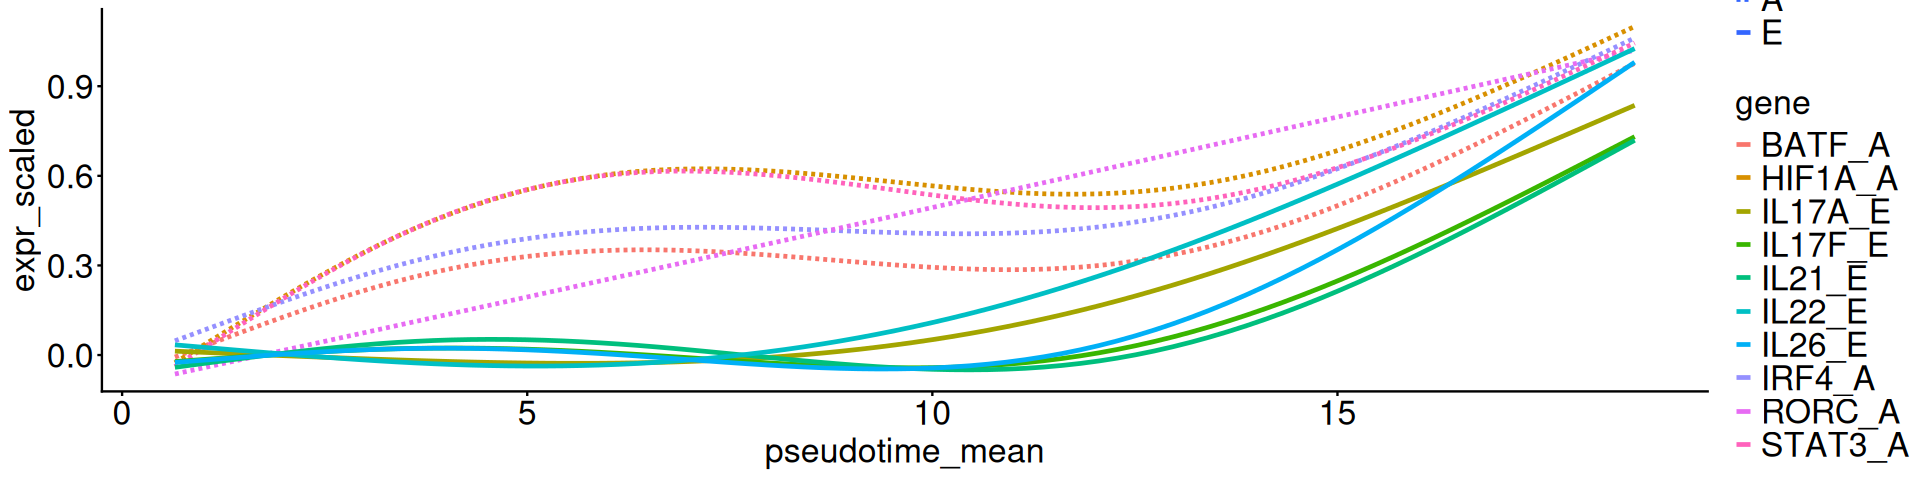

In [195]:
options(repr.plot.width = 16, repr.plot.height = 4)
df_binned  %>% 
mutate(gene_class = ifelse(grepl(gene, pattern = "_A"),"A","E"))  %>% 
ggplot(aes(
    x        = pseudotime_mean,
    y        = expr_scaled,
    linetype = gene_class,
    color = gene
  )
) +
  stat_smooth(
    method  = "gam",
    formula = y ~ s(x, k = 4),
    se      = F,
    size    = 1
  )  +
  scale_linetype_manual(values = c(A = "dashed", E = "solid", other = "solid")) +
theme_classic() +
ggtheme()

In [196]:
ggsave("figures/pseudotime_tf/th17.png", width = 32, height = 8, units = "cm", create.dir = TRUE)

library(svglite)
ggsave("figures/pseudotime_tf/th17.svg", width = 32, height = 8, units = "cm", create.dir = TRUE)

In [ ]:
## Cytotoxicity




In [197]:
df_binned <-  lin4  %>% dplyr::filter(gene %in% c("EOMES_A", "RUNX3_A", "NFATC1_A", "GZMA_E", "GZMB_E", "PRF1_E","GNLY_E","FASLG_E"))  %>% 

  mutate(pt_decile = ntile(Lineage4, 20)) %>%   # deciles 1–10
  group_by(gene, pt_decile) %>%
  summarize(
    pseudotime_mean = mean(Lineage4, na.rm = TRUE),
    expr_mean = mean(value, na.rm = TRUE),
    .groups = "drop"
  )

In [198]:
df_binned <- df_binned %>%
  group_by(gene) %>%
  mutate(
    expr_scaled = (expr_mean - min(expr_mean, na.rm = TRUE)) /
                  (max(expr_mean, na.rm = TRUE) - min(expr_mean, na.rm = TRUE))
  ) %>%
  ungroup()

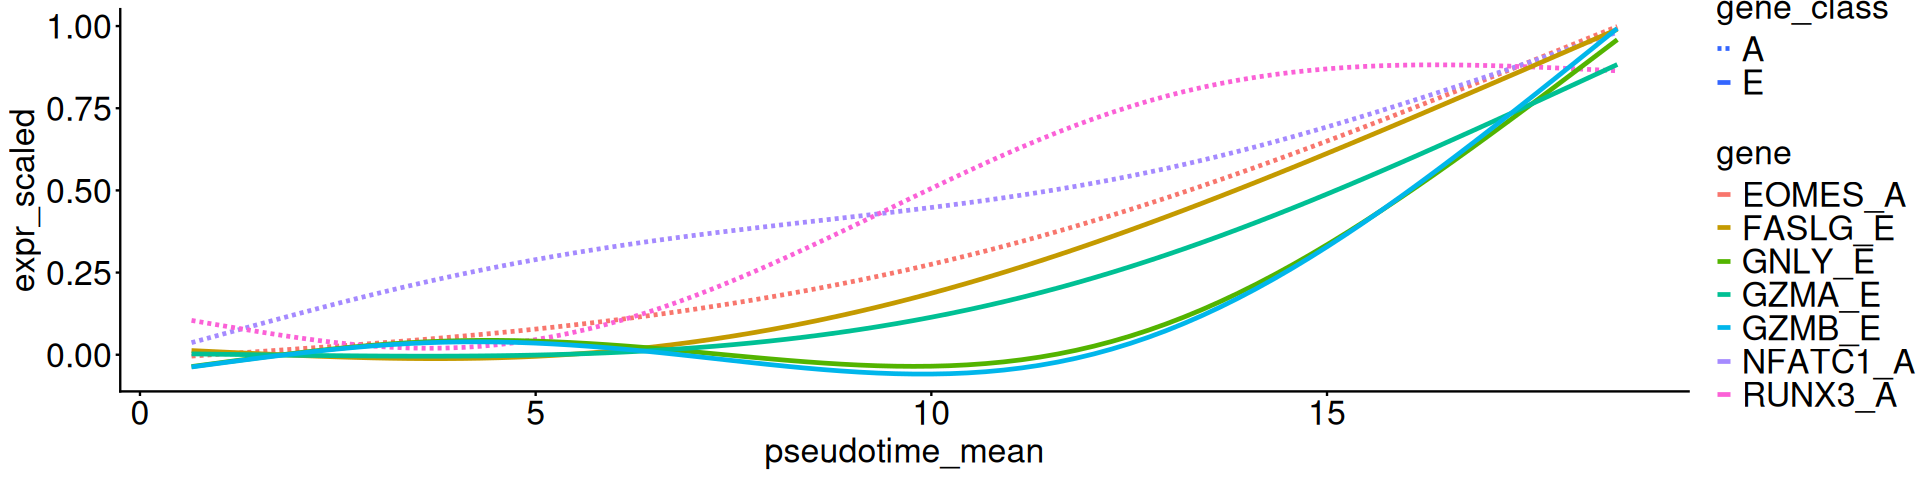

In [199]:
options(repr.plot.width = 16, repr.plot.height = 4)
df_binned  %>% 
mutate(gene_class = ifelse(grepl(gene, pattern = "_A"),"A","E"))  %>% 
ggplot(aes(
    x        = pseudotime_mean,
    y        = expr_scaled,
    linetype = gene_class,
    color = gene
  )
) +
  stat_smooth(
    method  = "gam",
    formula = y ~ s(x, k = 4),
    se      = F,
    size    = 1
  )  +
  scale_linetype_manual(values = c(A = "dashed", E = "solid", other = "solid")) +
theme_classic() +
ggtheme()

In [200]:
ggsave("figures/pseudotime_tf/cyt.png", width = 32, height = 8, units = "cm", create.dir = TRUE)

library(svglite)
ggsave("figures/pseudotime_tf/cyt.svg", width = 32, height = 8, units = "cm", create.dir = TRUE)